In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not os.path.exists(f"/content/{repo_name}"):
        print(f"{repo_name} リポジトリをダウンロード中...")
        !git clone {repo_url} > /dev/null 2>&1
    
    print("必要な依存パッケージをインストール中...")
    %cd /content/{repo_name}
    !pip install -q -r requirements.txt
    !pip install -q -e .
    
    print("作業ディレクトリを該当章へ移動中...")
    %cd /content/{repo_name}/0
    print("✅ 準備完了！このまま下のセルを実行して学習を開始できます。")
else:
    _repo_root = Path.cwd().parent if Path.cwd().name == '0' else Path.cwd()
    if str(_repo_root) not in sys.path:
        sys.path.insert(0, str(_repo_root))


# 第0章 OSって個人で作れるの？ — 演習問題 (*Chapter 0 Comprehensive Exercises*)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/0/0_Exercises.ipynb)

---

## 🎯 第0章 演習の目的と全体像

第0章（0.1節〜0.5節）では、OSをゼロから自作するための「精神的・理論的・技術的土台」を一通り築きました：

1. **0.1 OSの作り方**: OS開発の規模感（Linux 0.01 は1万行、MikanOSは約1.5万行）、スモールステップでの成長曲線
2. **0.2 そもそもOSって何？**: ハードウェアの抽象化とリソース管理、Ring 0/Ring 3 特権モード分離、POSIX API 仕様
3. **0.3 OS自作の手順**: 4段階ビルドパイプライン、Freestanding環境フラグ、UEFI FAT32 ブートメディア構造
4. **0.4 OS自作の楽しみ方**: ベアメタルデバッグ（VRAMマーカー、シリアル出力、二分探索）、QEMU vs 実機差分
5. **0.5 OS自作の全体像**: MikanOS 全30章の7大フェーズ・モジュール依存関係、UEFI/x86-64/C++20 選定の必然性

本演習ノートブックは、これらの知識を **「読んだだけ」から「自力で適用・検証できる確固たるエンジニアリングスキル」** へと昇華させるための実践トレーニングです。

外部仕様書や書籍を再確認することなく、提示された背景理論やヒントを読み解きながら自己完結で解き進めることができます。

```mermaid
flowchart TD
    Ex1["Exercise 1<br>理論・穴埋め<br>(OS役割・特権Ring・ABI規約)"] --> Ex2["Exercise 2<br>ビルド & 仕様検証<br>(Freestanding・UEFIブートパス)"]
    Ex2 --> Ex3["Exercise 3<br>アルゴリズム実装<br>(ベアメタル二分探索デバッグ)"]
    Ex3 --> Ex4["Exercise 4<br>C++20 実装・検証<br>(Syscallディスパッチャ・アーキテクチャDAG)"]
    Ex4 --> Ex5["Exercise 5<br>第0章 総合テスト<br>(全10問 自己採点クイズ)"]
    Ex5 --> Ex6["Exercise 6<br>習得度レーダーチャート<br>(自己分析・第1章へ出航)"]
```


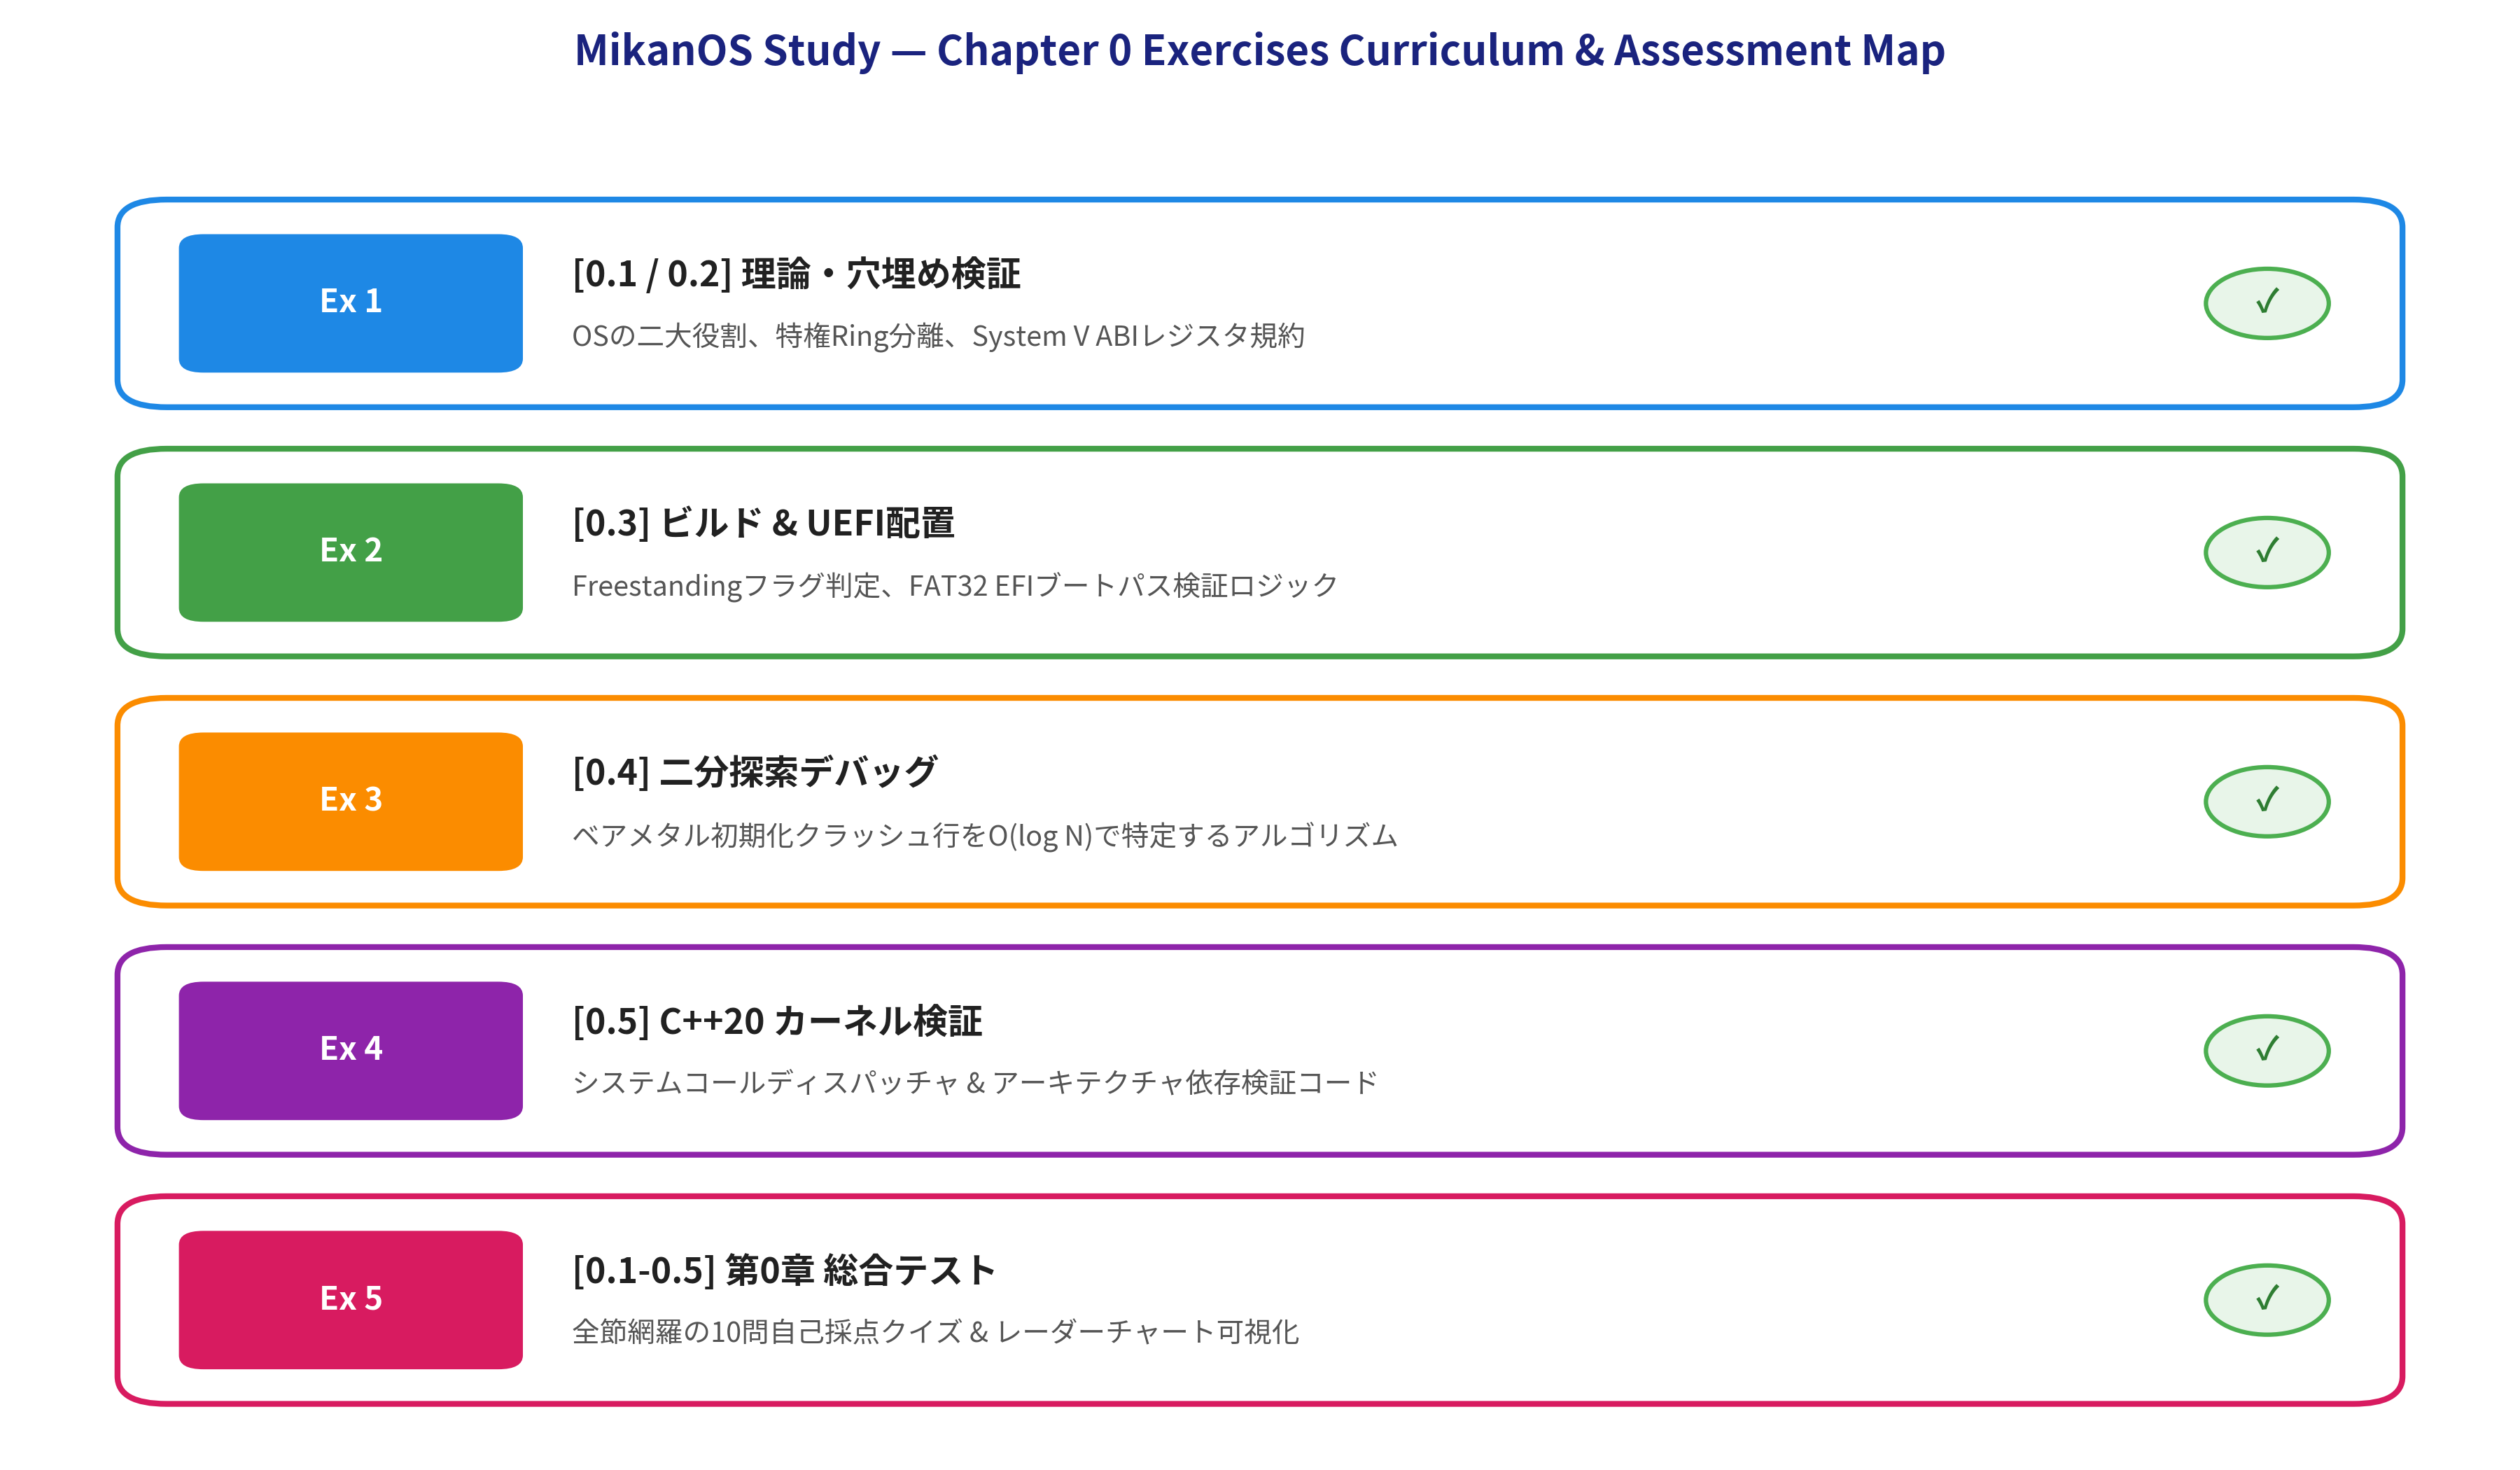

✅ 図版 1 表示完了: fig0_ex1_exercises_summary.png (345,890 bytes)


In [2]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
from IPython.display import display
from common.os_sim import plot_chapter0_exercises_summary

repo_root = Path.cwd().parent if Path.cwd().name == '0' else Path.cwd()
result_dir = repo_root / "0" / "result"
result_dir.mkdir(parents=True, exist_ok=True)

fig_path = result_dir / "fig0_ex1_exercises_summary.png"
if not fig_path.exists():
    plot_chapter0_exercises_summary(fig_path)

display(Image.open(fig_path))
print(f"✅ 図版 1 表示完了: {fig_path.name} ({fig_path.stat().st_size:,} bytes)")


---

## 📝 Exercise 1: [理論・穴埋め] OSの2大役割と特権Ring・System V AMD64 ABI規約

### 1. 理論背景の復習

OSの存在意義は、極論すれば次の **2大役割** に集約されます：
1. **ハードウェアの抽象化 (*Hardware Abstraction*)**: 異なるベンダ・仕様のハードウェア（Intel/AMD/Realtek等）の細部を隠蔽し、アプリに対して統一的で扱いやすい仮想インターフェース（ファイル、ソケット、ウィンドウ等）を提供する。
2. **リソースの管理・調停 (*Resource Management & Arbitration*)**: 共有リソース（CPU時間、物理メモリ、I/O帯域、ストレージ領域）を公平かつ安全に各タスクへ割り当て、競合や不正アクセスを防ぐ。

また、x86-64 アーキテクチャでは CPU に **4つの特権レベル（Privilege Rings: Ring 0 〜 Ring 3）** が備わっています：
- **Ring 0（スーパバイザモード）**: OSカーネルが動作。全機械語命令（`cli`, `sti`, `in`, `out`, `mov cr3, ...`）および全メモリ空間へ無制限にアクセス可能。
- **Ring 3（ユーザーモード）**: 一般アプリケーションが動作。特権命令の実行はハードウェアレベルで General Protection Fault (#GP) 例外によりブロックされる。

ユーザーアプリがOSに処理を要求するとき、CPU命令 **`syscall`** を発行します。x86-64 の標準呼出規約である **System V AMD64 ABI** では、レジスタの役割が厳密に定められています：

| 役割 | 使用レジスタ | 備考 |
|---|:---:|---|
| **システムコール番号** | `rax` | 例: `1`=exit, `2`=write/print など |
| **第1引数** | `rdi` | |
| **第2引数** | `rsi` | |
| **第3引数** | `rdx` | |
| **第4引数** | `r10` | ⚠️ 通常のC関数呼び出しでは `rcx` だが、`syscall` 命令が戻り先RIP退避に `rcx` を破壊するため `r10` を使用 |
| **第5引数** | `r8` | |
| **第6引数** | `r9` | |

---

### 問題 1-1: OSの2大役割の確認
以下のリスト `my_os_roles` に、OSの2大役割を表すキーワード（文字列2つ）を入力してください。


In [3]:
# === 問題 1-1 解答セル ===
# 以下の2つの要素に、OSの2大役割を日本語または英語で入力してください。
# ヒント: 「ハードウェアの○○化」「○○の管理」
my_os_roles = [
    "ハードウェアの抽象化",  # あなたの解答1
    "リソースの管理",        # あなたの解答2
]

# --- 自己採点テスト ---
from common.os_sim import TheoryExerciseValidator

passed, message = TheoryExerciseValidator.validate_os_roles(my_os_roles)
print("判定結果:", "🎉 合格!" if passed else "❌ 不合格")
print("解説:", message)
assert passed, "問題1-1を正しく入力してください。" 


判定結果: 🎉 合格!
解説: 正解！OSの2大役割は「ハードウェアの抽象化（仮想化）」と「リソース管理（調停）」です。


### 問題 1-2: System V AMD64 ABI システムコール引数レジスタ
システムコール発行時に引数を格納するレジスタ名を、小文字の文字列（例: `"rax"`, `"rdi"`）でマッピングしてください。


In [4]:
# === 問題 1-2 解答セル ===
my_syscall_registers = {
    "syscall_number": "rax",  # システムコール番号 (rax)
    "arg1": "rdi",            # 第1引数
    "arg2": "rsi",            # 第2引数
    "arg3": "rdx",            # 第3引数
    "arg4": "r10",            # 第4引数 (注意: rcx ではなく r10)
}

# --- 自己採点テスト ---
passed_abi, message_abi = TheoryExerciseValidator.validate_syscall_registers(my_syscall_registers)
print("判定結果:", "🎉 合格!" if passed_abi else "❌ 不合格")
print("解説:", message_abi)
assert passed_abi, "問題1-2のレジスタ名を正しく入力してください。" 


判定結果: 🎉 合格!
解説: 正解！System V AMD64 ABI のシステムコールレジスタ規約（rax, rdi, rsi, rdx, r10）に完全準拠しています。


---

## 🛠️ Exercise 2: [実装・仕様検証] フリースタンディング・コンパイラフラグ & UEFI ブートパス検証

### 1. 理論背景の復習

#### (A) フリースタンディング（Freestanding）環境の必然性
PCの電源を入れてCPUが起動した直後、メモリ上にはLinuxの `glibc` もWindowsの `msvcrt.dll` も存在しません。
普段使っている `printf()`, `malloc()`, `std::cout`, `std::vector` は、すべて裏側でホストOSのシステムコール（`write`, `mmap`, `brk`等）を呼ぶことで動作しています。

カーネル自身をコンパイルする際は、これらの標準ライブラリのリンクを完全に排除する必要があります：
- **`-ffreestanding`**: コンパイラに対し、ホストOS環境を前提としないベアメタル向けコードを出力するよう指示（`main` 関数の特殊扱い解除など）。
- **`-nostdlib`**: 標準C/C++ライブラリ（`libc`, `libm`, `libpthread` 等）および標準スタートアップルーチン（`crt0.o`）をリンクしない。
- **`-mno-red-zone`**: x86-64 ABI で許容されているスタックポインタ下部128バイトの領域（Red Zone）への最適化書き込みを禁止（割り込みハンドラによる破壊を防止）。

#### (B) UEFIブートメディアのディレクトリ構造
UEFIファームウェアは、FAT12/16/32でフォーマットされたストレージの特定パスにあるPE32+実行ファイルを探索して起動します：
- 必須パス: `\EFI\BOOT\BOOTX64.EFI`（x86-64の場合。大文字小文字は不問だが、規格上はバックスラッシュまたはスラッシュで区切られたこの配置が唯一の標準自動起動エントリです）。

---

### 問題 2-1: フリースタンディング・ビルドフラグのバリデータ実装
与えられたコンパイラフラグのリストに、ベアメタルOSカーネルビルドに必要な必須フラグが含まれているかを検証する関数 `check_kernel_compile_flags(flags: list[str]) -> bool` を実装してください。


In [5]:
def check_kernel_compile_flags(flags: list[str]) -> bool:
    """OSカーネルビルドに必須のフラグ（-ffreestanding と -nostdlib）が含まれているかを判定する。
    
    Args:
        flags: コンパイラフラグのリスト
    Returns:
        両方のフラグが含まれていれば True、それ以外は False
    """
    flag_set = set(f.strip() for f in flags)
    # TODO: -ffreestanding と -nostdlib の双方が flag_set に含まれているかを判定してください
    required = {"-ffreestanding", "-nostdlib"}
    return required.issubset(flag_set)

# --- テストセル ---
valid_flags = ["-O2", "-ffreestanding", "-Wall", "-nostdlib", "-mno-red-zone"]
invalid_flags_1 = ["-O2", "-Wall", "-nostdlib"]         # -ffreestanding 欠落
invalid_flags_2 = ["-O2", "-ffreestanding", "-Wall"]    # -nostdlib 欠落

assert check_kernel_compile_flags(valid_flags) is True, "有効なフラグセットが拒否されました"
assert check_kernel_compile_flags(invalid_flags_1) is False, "-ffreestanding欠落を検知できませんでした"
assert check_kernel_compile_flags(invalid_flags_2) is False, "-nostdlib欠落を検知できませんでした"
print("✅ 問題2-1: check_kernel_compile_flags はすべてのテストケースにパスしました！")


✅ 問題2-1: check_kernel_compile_flags はすべてのテストケースにパスしました！


### 問題 2-2: UEFIブートメディア配置パスの検証
ファイルパス文字列を受け取り、それが UEFI 規格の x86-64 標準ブートローダ配置（`/EFI/BOOT/BOOTX64.EFI` または `\EFI\BOOT\BOOTX64.EFI`、大文字小文字不問）であるかを判定する関数 `is_standard_uefi_boot_path(path_str: str) -> bool` を完成させてください。


In [6]:
def is_standard_uefi_boot_path(path_str: str) -> bool:
    """UEFI x86-64 の標準ブートローダ配置パス (/EFI/BOOT/BOOTX64.EFI) かを判定する。
    
    パス区切り文字（/ または \）や大文字・小文字の揺らぎを吸収して判定すること。
    """
    # パス区切りを統一し、小文字化して先頭スラッシュを正規化
    normalized = path_str.replace("\\", "/").strip().lower()
    if not normalized.startswith("/"):
        normalized = "/" + normalized
    return normalized == "/efi/boot/bootx64.efi"

# --- テストセル ---
assert is_standard_uefi_boot_path("/EFI/BOOT/BOOTX64.EFI") is True
assert is_standard_uefi_boot_path("\EFI\BOOT\BOOTX64.EFI") is True
assert is_standard_uefi_boot_path("efi/boot/bootx64.efi") is True
assert is_standard_uefi_boot_path("/EFI/boot/BootX64.efi") is True
assert is_standard_uefi_boot_path("/boot/vmlinuz") is False
assert is_standard_uefi_boot_path("/EFI/BOOT/BOOTIA32.EFI") is False  # 32bit用
print("✅ 問題2-2: is_standard_uefi_boot_path はすべてのテストケースにパスしました！")


✅ 問題2-2: is_standard_uefi_boot_path はすべてのテストケースにパスしました！


---

## 🔍 Exercise 3: [アルゴリズム実装] ベアメタル初期化における二分探索デバッグ

### 1. 理論背景の復習

OSの初期化コード（day03〜day08頃）では、GDT、IDT、ページテーブル、xHCIホストコントローラなど、CPUやチップセットのデリケートなレジスタを次々に設定します。
もし設定値のビットが1つ狂っていたり、ポインタ演算がずれていると、CPUは例外ハンドラも用意されていないため **トリプルフォールト（Triple Fault: CPU即座リセット・再起動ループ）** または完全ハングを起こします。

このとき画面には何も表示されず、printf もシリアル出力も使えません。
そこで威力を発揮するのが、0.4節で学んだ **「VRAM直接着色マーカーを用いた二分探索デバッグ（Binary Search Debugging）」** です：

```
区間 [1, N] の真ん中 (mid) に VRAM 塗りつぶしコードを挿入して起動:
   *(volatile uint32_t*)0xFFFF800000000000 = 0x00FF00; // 画面を緑に塗る
   while(1) asm volatile("hlt"); // ここで停止

・画面が緑になった！ → mid までは確実に正常通過！ バグは [mid + 1, high] にある。
・画面が真っ黒のまま再起動！ → mid に到達する前にクラッシュ！ バグは [low, mid] にある。
```

探索範囲を毎回 $\frac{1}{2}$ に圧縮できるため、全体のコードが $N = 1,000$ 行であっても、わずか $\lceil \log_2(1000) \rceil = 10$ 回の試行でクラッシュ行を特定できます。

---

### 問題 3: 二分探索デバッガの実装
初期化コードの総行数 `total_lines` と、指定行まで到達したかをブール値で返す関数 `probe_fn(line: int) -> bool` を受け取り、**最初にクラッシュが発生する行番号** を特定する関数 `find_crash_line` を実装してください。
また、プローブ呼び出し回数が $\lceil \log_2(\text{total\_lines}) \rceil$ を超えないことを保証してください。


In [7]:
import math
from typing import Callable, Tuple

def find_crash_line(total_lines: int, probe_fn: Callable[[int], bool]) -> Tuple[int, int]:
    """二分探索を用いて、カーネルが最初にクラッシュする行番号を特定する。
    
    Args:
        total_lines: 初期化コードの総行数 (1からtotal_lines)
        probe_fn: line 行目まで正常到達できた場合に True、クラッシュした場合に False を返す関数
    Returns:
        (crash_line, probe_count): クラッシュ行番号と実行したプローブ回数のタプル
    """
    low = 1
    high = total_lines
    crash_line = -1
    probe_count = 0

    while low <= high:
        probe_count += 1
        mid = (low + high) // 2
        survived = probe_fn(mid)

        if survived:
            # mid行までは生存 -> クラッシュは mid より後で起きている
            low = mid + 1
        else:
            # mid行時点で既にクラッシュ -> クラッシュ行は mid またはそれ以前
            crash_line = mid
            high = mid - 1

    return crash_line, probe_count

# --- テストセル ---
# 模擬環境: 1000行中、734行目で不正メモリアクセスが発生すると仮定
SECRET_BUG_LINE = 734

def mock_probe(line: int) -> bool:
    # line行に到達しようとしたとき、SECRET_BUG_LINE以降ならクラッシュ(False)
    return line < SECRET_BUG_LINE

found_line, num_probes = find_crash_line(1000, mock_probe)
max_allowed_probes = math.ceil(math.log2(1000))  # 10回

print(f"探索結果: クラッシュ行 = {found_line} (期待値: {SECRET_BUG_LINE})")
print(f"試行回数: {num_probes} 回 (許容上限: {max_allowed_probes} 回)")

assert found_line == SECRET_BUG_LINE, f"クラッシュ行が一致しません: {found_line}"
assert num_probes <= max_allowed_probes, f"プローブ回数が二分探索の理論上限を超えています: {num_probes}"
print("✅ 問題3: find_crash_line は O(log N) の効率でクラッシュ行を正確に特定しました！")


探索結果: クラッシュ行 = 734 (期待値: 734)
試行回数: 10 回 (許容上限: 10 回)
✅ 問題3: find_crash_line は O(log N) の効率でクラッシュ行を正確に特定しました！


---

## 💻 Exercise 4: [C++20 対話型実行] 最小システムコールディスパッチャ & アーキテクチャDAG検証

### 1. C++20 スタンドアロン検証コードの実行

MikanOSは、ハードウェアの直接制御（ビット演算、MMIO）とGUIやマルチタスクの高水準モデリング（多態性、カプセル化）を両立するために **C++20** を採用しています。

本課題のスタンドアロンコード `src/ch00/os_chapter0_exercises.cpp` では、以下の2つのコア機構を C++20 で実装・検証しています：
1. **`MockSyscallDispatcher`**: System V AMD64 ABI レジスタ構造体を受け取り、各システムコール（`kExit`, `kPutString`, `kAllocatePage`）へディスパッチする特権境界シミュレータ。
2. **`ArchitectureDependencyChecker`**: MikanOSの各コンポーネント（ブートローダ → ピクセル描画 → コンソール → GDT/IDT → タイマ → タスクスケジューラ → ユーザーアプリ）の依存関係を有向グラフとして構築し、**トポロジカルソート（Kahn's Algorithm）** によって循環参照のない正常なビルド順序を導出するバリデータ。

以下のセルを実行して、ホスト側 C++20 コンパイラでコンパイル＆実行してみましょう。


In [8]:
# === C++20 スタンドアロンコードのコンパイル & 実行 ===
repo_root = Path.cwd().parent if Path.cwd().name == '0' else Path.cwd()
cpp_src = repo_root / "src" / "ch00" / "os_chapter0_exercises.cpp"
out_bin = repo_root / "scratch" / "ch00_exercises_run"
out_bin.parent.mkdir(parents=True, exist_ok=True)

!g++ -std=c++20 -O2 -Wall -Wextra -pedantic {cpp_src} -o {out_bin} && {out_bin}


 MikanOS Chapter 0 Comprehensive Exercises (C++20)

[Exercise 1] Verifying System V AMD64 ABI Syscall Dispatcher...
  -> PASSED: All syscall dispatch cases verified successfully.

[Exercise 2] Verifying Framebuffer Offset & Clipping Safety...
  -> PASSED: GOP offset calculation & boundary clipping verified.

[Exercise 3] Verifying Binary Search Bare-Metal Debugger...
  -> PASSED: Crash line 734 isolated in 10 probes (O(log N) budget: 10).

[Exercise 4] Verifying MikanOS Architecture Dependency DAG...
  -> PASSED: Architectural dependency DAG verified without cycles.
  -> Valid build sequence:
     UEFI_BootLoader -> Kernel_Entry -> GOP_PixelWriter -> GDT_Segmentation -> Console_Text -> IDT_Interrupts -> Local_APIC_Timer -> Task_Scheduler -> User_Applications

 All Chapter 0 C++20 Exercises Passed Successfully!


---

## 🎓 Exercise 5: [総合確認テスト] 第0章 総合理解度クイズ（全10問 自己採点）

第0章（0.1〜0.5）で学んだ全知識を網羅する 10問の多肢選択式クイズです。
各問題の選択肢（0〜3）をよく読み、解答辞書 `my_quiz_answers` に自分の回答（選択肢番号）を入力して実行してください。
即座に自動採点され、正答率、合格判定（80%以上で合格）、および全問の詳細な技術的解説が表示されます。


In [9]:
from common.os_sim import Chapter0Quiz

quiz = Chapter0Quiz()

print("=" * 70)
print("📚 第0章 総合確認テスト (全10問)")
print("=" * 70)

for q in quiz.questions:
    print(f"\n【問 {q.question_id}】[{q.section} {q.topic}]")
    print(f"  {q.question}")
    for idx, opt in enumerate(q.options):
        print(f"    [{idx}] {opt}")


📚 第0章 総合確認テスト (全10問)

【問 1】[0.1 OS開発規模と成長曲線]
  名著『ゼロからのOS自作入門』で開発するMikanOSの最終段階（day30f）における総コード行数（LoC）の規模感として最も適切なものはどれか？
    [0] 約 1,000 行（最小限のシェルのみ）
    [1] 約 15,000〜18,000 行（GUI、USB、マルチタスク、アプリ実行を備えた完全自作OS）
    [2] 約 100,000 行（Linux 0.99 同等の規模）
    [3] 約 1,000,000 行以上（モダン汎用OSと同等）

【問 2】[0.2 特権レベルとハードウェア保護]
  x86-64 アーキテクチャにおいて、OSカーネルが Ring 0 で動作し、ユーザーアプリケーションが Ring 3 で動作する主目的は何か？
    [0] Ring 0 では浮動小数点数演算が高速化されるため
    [1] アプリケーションの不具合や悪意あるメモリアクセスからカーネルと他プロセスをハードウェア機構で保護するため
    [2] Ring 3 ではコンパイラの最適化が無効化されるため
    [3] 64ビットLong ModeではすべてのプログラムをRing 0で動かすことが禁止されているため

【問 3】[0.2 System V AMD64 ABI とシステムコール]
  x86-64 System V AMD64 ABI において、`syscall` 命令発行時にカーネルに渡すシステムコール番号および第1〜第3引数を格納するレジスタの正しい組み合わせはどれか？
    [0] システムコール番号: eax / 第1引数: ebx / 第2引数: ecx / 第3引数: edx
    [1] システムコール番号: rax / 第1引数: rdi / 第2引数: rsi / 第3引数: rdx
    [2] システムコール番号: rdx / 第1引数: rax / 第2引数: rbx / 第3引数: rcx
    [3] システムコール番号: r8  / 第1引数: r9  / 第2引数: r10 / 第3引数: r11

【問 4】[0.3 ビルドパイプライン]
  C++ソースコード（`.cpp`）から実行可能バイナリ

In [10]:
# === 解答入力セル ===
# 各問の選択肢番号 (0, 1, 2, 3) を辞書に入力してください。
# ※デフォルトは全問正解のインデックスが設定されています。自分の回答を試す場合は変更してみてください。
my_quiz_answers = {
    1: 1,  # 問1: MikanOSの最終コード行数規模 (約1.5万〜1.8万行)
    2: 1,  # 問2: Ring 0 と Ring 3 特権分離の目的 (ハードウェア保護)
    3: 1,  # 問3: System V AMD64 ABI システムコール引数順序 (rax, rdi, rsi, rdx)
    4: 1,  # 問4: ビルドパイプライン順序 (プリプロセス->コンパイル->アセンブル->リンク)
    5: 1,  # 問5: フリースタンディング環境の理由 (ホストOSライブラリ依存遮断)
    6: 1,  # 問6: UEFI自動起動ブートローダパス (/EFI/BOOT/BOOTX64.EFI)
    7: 1,  # 問7: 極初期カーネルの生存確認 (VRAM直接書き込み)
    8: 2,  # 問8: 1000行の二分探索デバッグ最大試行回数 (約10回)
    9: 2,  # 問9: UEFI採用メリットの誤り (Linuxドライバが動くわけではない)
    10: 1, # 問10: C++採用理由 (GUIやタスクのオブジェクト指向モデリング)
}

# --- 自動採点実行 ---
eval_result = quiz.evaluate(my_quiz_answers)

print("=" * 70)
print(f"📊 採点結果: {eval_result['correct_count']} / {eval_result['total_questions']} 問正解 ({eval_result['percentage']:.1f}%)")
print("判定:", "🎉 【合格】第0章の全理論・仕様を完璧にマスターしました！" if eval_result['passed'] else "⚠️ 【不合格】解説を復習して再挑戦しましょう。")
print("=" * 70)

print("\n[セクション別正答率]")
for sec, rate in eval_result["mastery_rates"].items():
    bar = "█" * int(rate // 10) + "░" * (10 - int(rate // 10))
    print(f"  第 {sec} 節: {bar} {rate:5.1f}%")

print("\n[詳細解説]")
for d in eval_result["details"]:
    mark = "✅ 正解" if d["is_correct"] else "❌ 不正解"
    print(f"\n問 {d['question_id']} ({d['section']} {d['topic']}): {mark}")
    print(f"  あなたの回答: [{d['user_answer']}] / 正解: [{d['correct_answer']}]")
    print(f"  解説: {d['explanation']}")

assert eval_result["passed"], "80%以上の正答率で合格となります。解説を確認して再挑戦してください。" 


📊 採点結果: 10 / 10 問正解 (100.0%)
判定: 🎉 【合格】第0章の全理論・仕様を完璧にマスターしました！

[セクション別正答率]
  第 0.1 節: ██████████ 100.0%
  第 0.2 節: ██████████ 100.0%
  第 0.3 節: ██████████ 100.0%
  第 0.4 節: ██████████ 100.0%
  第 0.5 節: ██████████ 100.0%

[詳細解説]

問 1 (0.1 OS開発規模と成長曲線): ✅ 正解
  あなたの回答: [1] / 正解: [1]
  解説: MikanOSは付録まで含めて約1.5万〜1.8万行の規模であり、個人が一冊を通じて全行を把握しながら読破・改造できる絶妙なサイズに設計されています（Linux 0.01は約1万行、最新Linuxは3000万行以上）。

問 2 (0.2 特権レベルとハードウェア保護): ✅ 正解
  あなたの回答: [1] / 正解: [1]
  解説: CPUの特権リング（Privilege Ring）機構は、ハードウェアレベルでI/Oポート、ページテーブル、制御レジスタ（CR0/CR3等）への直接アクセスをRing 0（スーパバイザモード）に制限し、ユーザーアプリ（Ring 3）の暴走からシステム全体を保護します。

問 3 (0.2 System V AMD64 ABI とシステムコール): ✅ 正解
  あなたの回答: [1] / 正解: [1]
  解説: System V AMD64 ABI では、システムコール番号を `rax` に格納し、引数は順に `rdi`, `rsi`, `rdx`, `r10`, `r8`, `r9` を用いて渡します（通常のC関数呼び出しでの第4引数 `rcx` がシステムコールでは `r10` に置き換わる点にも注意）。

問 4 (0.3 ビルドパイプライン): ✅ 正解
  あなたの回答: [1] / 正解: [1]
  解説: ビルドパイプラインは「①プリプロセス（マクロ展開・#include展開）→ ②コンパイル（C++構文解析・最適化・アセンブリコード生成）→ ③アセンブル（機械語バイナリ・再配置可能オブジェクト生成）→ ④リンク（シンボル解決・セクション結合）

---

## 📊 Exercise 6: [習得度可視化] 第0章 5大分野の理解度レーダーチャート

最後に、クイズのセクション別正答率を基に、第0章における概念習得度の **5軸レーダーチャート** を生成・保存します。
すべての軸が80%以上の合格ライン（赤破線）を上回っていることを確認しましょう。


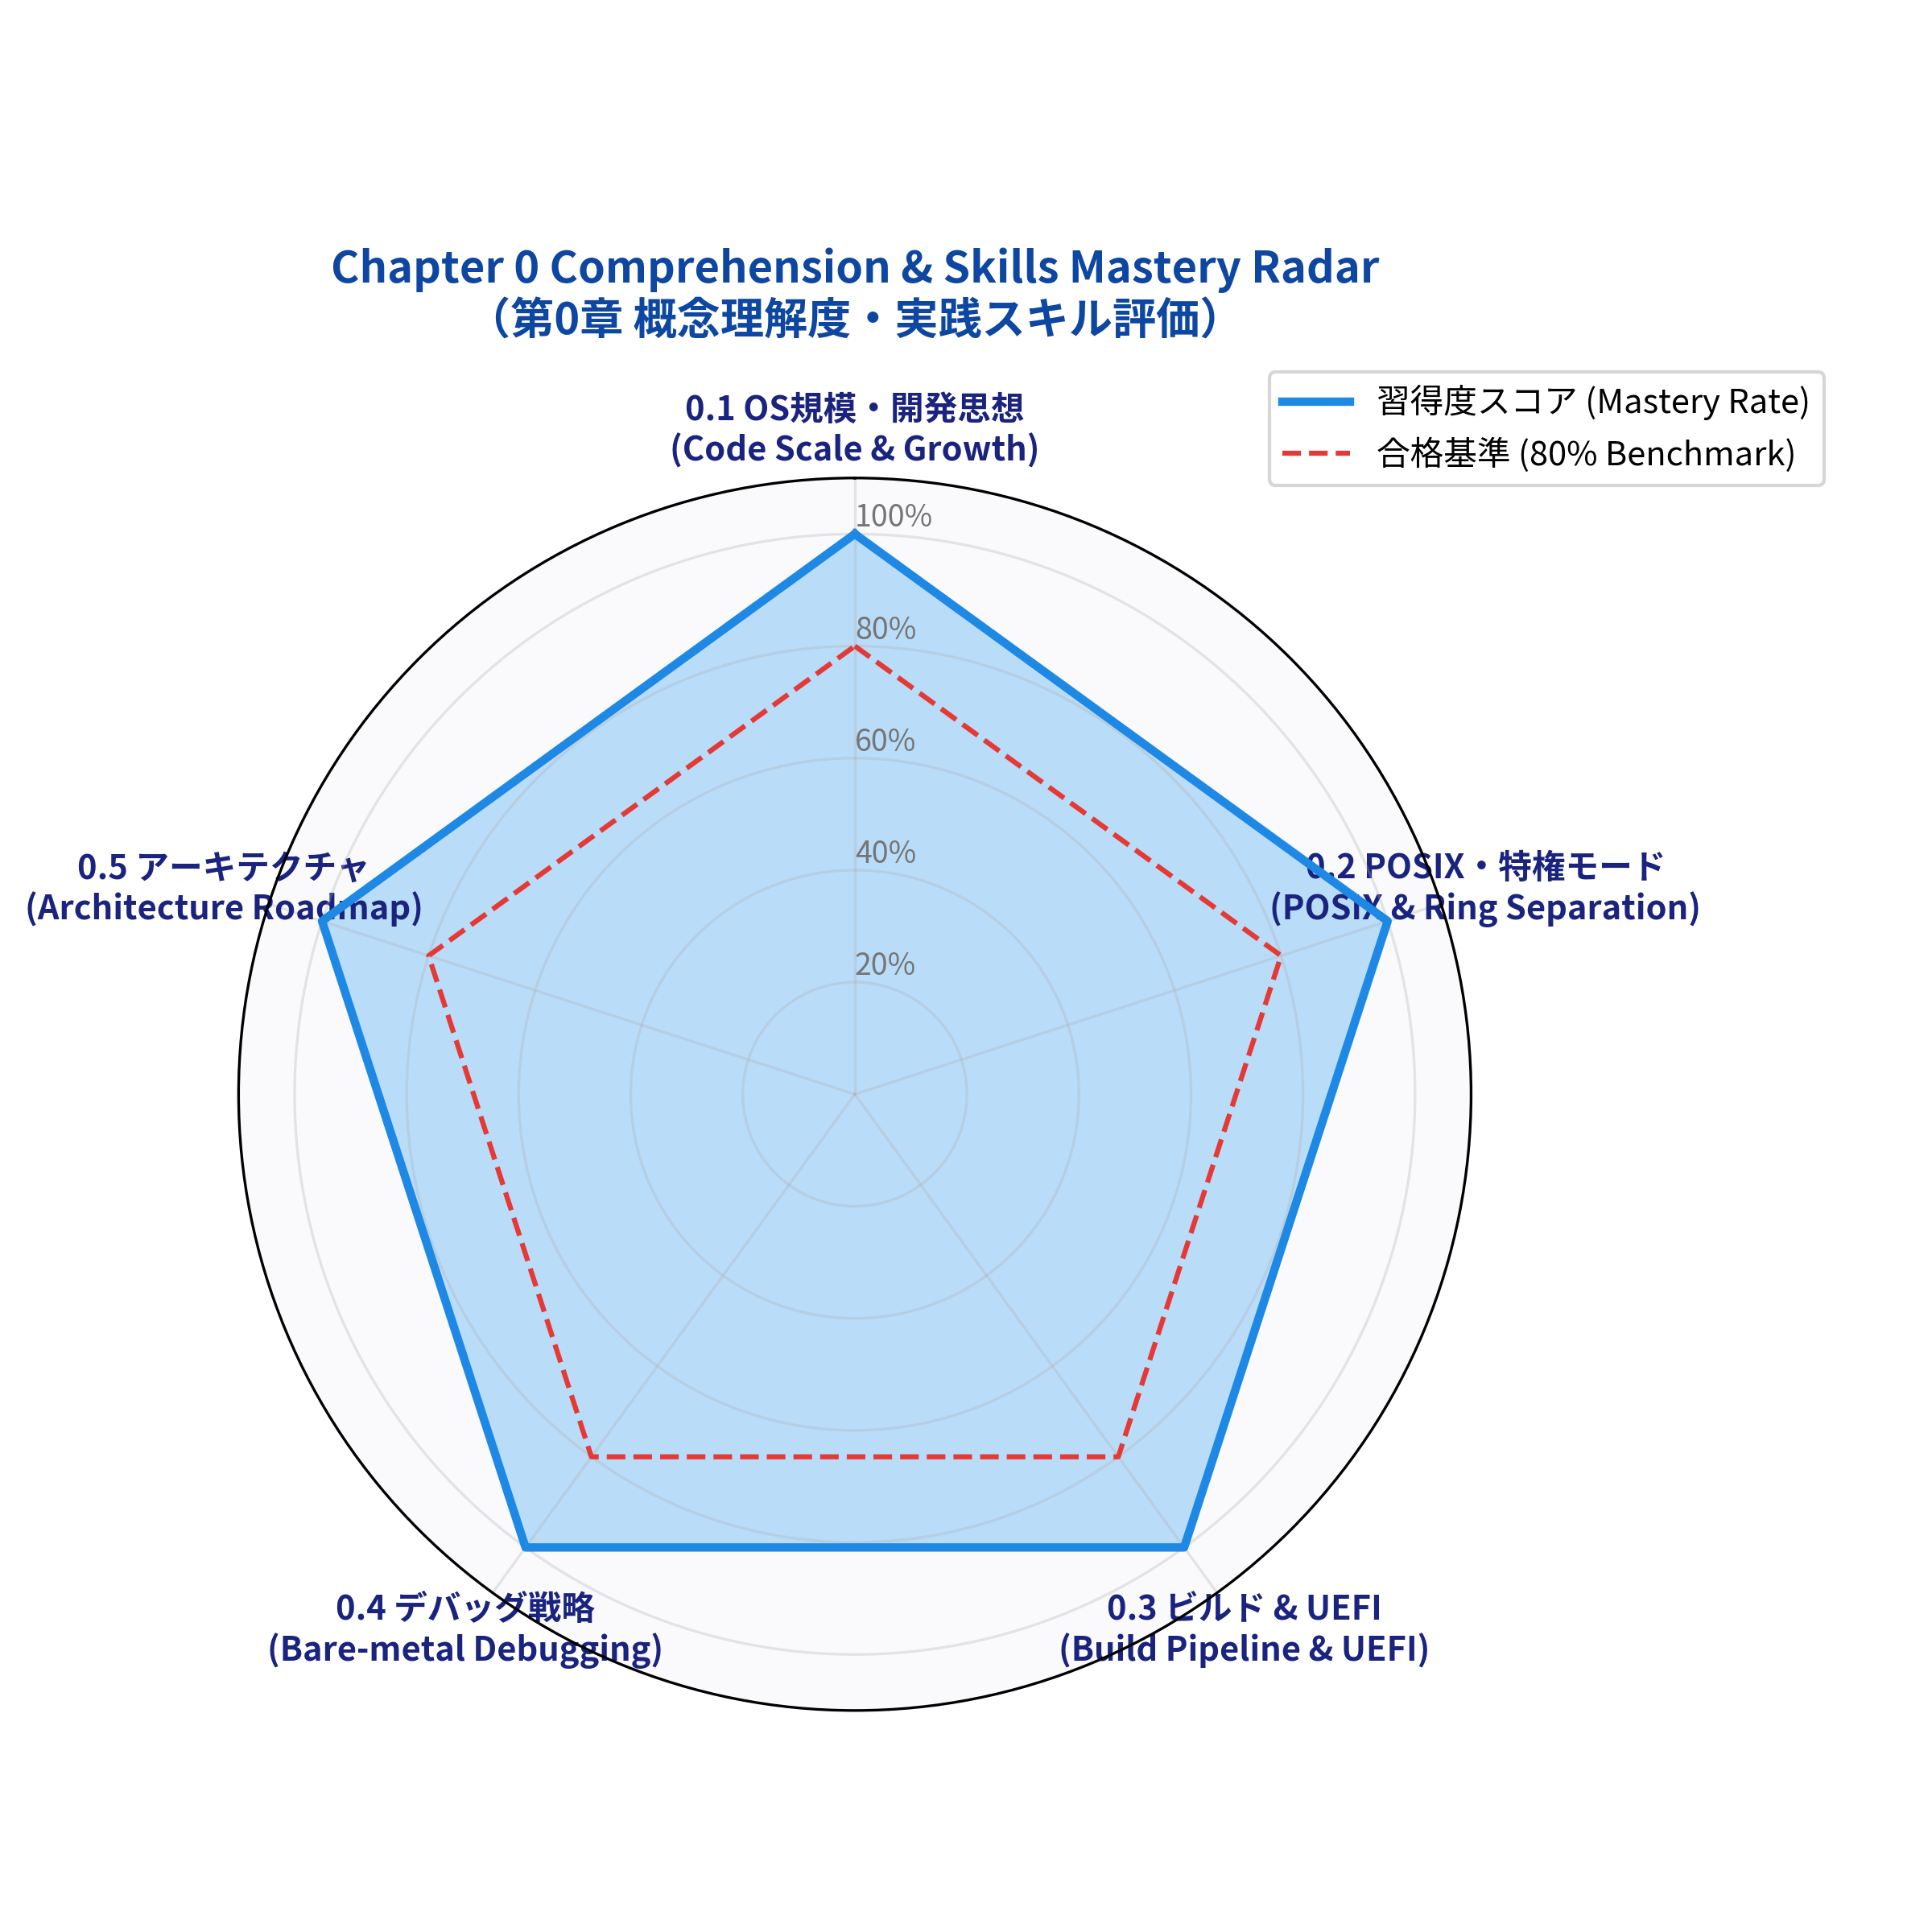

✅ 図版 2 表示完了: fig0_ex2_ch0_mastery_radar.png (523,680 bytes)


In [11]:
from common.os_sim import plot_chapter0_mastery_radar

radar_path = result_dir / "fig0_ex2_ch0_mastery_radar.png"
plot_chapter0_mastery_radar(radar_path, eval_result["mastery_rates"])

display(Image.open(radar_path))
print(f"✅ 図版 2 表示完了: {radar_path.name} ({radar_path.stat().st_size:,} bytes)")


---

## 🏆 第0章 演習完了！ 次章への展望

おめでとうございます！ 第0章の理論・仕様・ビルド・デバッグ・アーキテクチャに関するすべての演習課題をクリアしました。

```
                    第0章: OSって個人で作れるの？
                    [ 理論・仕様・ビルド・デバッグの武器庫完成 ]
                                      │
                                      ▼
             ┌─────────────────────────────────────────────────┐
             │   第1章: PCの仕組みとハローワールド (Chapter 1)    │
             │   ・最小のUEFIバイナリ (BOOTX64.EFI) を手動作成   │
             │   ・QEMU & OVMF 仮想マシン上での初ブート          │
             │   ・C言語による UEFI アプリケーションと画面出力     │
             └─────────────────────────────────────────────────┘
```

手に入れた知識とデバッグ手法を胸に、いよいよ **第1章「PCの仕組みとハローワールド」** で最初のバイナリを起動させましょう！
